# Práctica 4. Búsqueda no informada en un mapa de carreteras

**Asignatura:** Inteligencia Artificial
**Unidad:** 2. Resolución de problemas por métodos de búsqueda

## Objetivo

Implementar los algoritmos de búsqueda en anchura (BFS), búsqueda en profundidad (DFS),
búsqueda de profundidad iterativa (IDS) y búsqueda de costo uniforme (UCS) sobre un
grafo dirigido que representa un mapa de carreteras.

Se comparará el desempeño de los algoritmos considerando:

- Ruta encontrada.
- Costo total de la ruta en kilómetros.
- Número de nodos expandidos.
- Límite de profundidad en el que IDS encuentra la solución.

## Paso 1: representar el mapa

In [4]:
# ---------------------------------------------------------
# MAPA DE CARRETERAS
# ---------------------------------------------------------
# El grafo se representa mediante un diccionario.
#
# Cada ciudad es un nodo (estado).
# Cada conexión entre ciudades es una acción posible.
# El número asociado a cada conexión representa su costo
# en kilómetros.
#
# Como las carreteras pueden recorrerse en ambos sentidos,
# cada tramo aparece en las dos ciudades correspondientes.
# ---------------------------------------------------------

grafo = {

    "Morelia": {
        "Querétaro": 195,
        "Toluca": 245
    },

    "Querétaro": {
        "CDMX": 213,
        "Morelia": 195,
        "Pachuca": 240,
        "Toluca": 190
    },

    "Toluca": {
        "CDMX": 66,
        "Cuernavaca": 110,
        "Morelia": 245,
        "Querétaro": 190
    },

    "CDMX": {
        "Cuernavaca": 89,
        "Pachuca": 95,
        "Puebla": 130,
        "Querétaro": 213,
        "Toluca": 66
    },

    "Pachuca": {
        "CDMX": 95,
        "Querétaro": 240,
        "Tlaxcala": 150
    },

    "Cuernavaca": {
        "CDMX": 89,
        "Puebla": 160,
        "Toluca": 110
    },

    "Tlaxcala": {
        "Pachuca": 150,
        "Puebla": 35
    },

    "Puebla": {
        "CDMX": 130,
        "Cuernavaca": 160,
        "Tlaxcala": 35
    }
}

## Paso 2: definir inicio y meta

In [5]:
# ---------------------------------------------------------
# ESTADO INICIAL Y ESTADO META
# ---------------------------------------------------------

# Ciudad desde la cual comenzará la búsqueda.
estado_inicial = "Morelia"

# Ciudad que queremos alcanzar.
estado_meta = "Puebla"

# Mostramos ambos valores para comprobar que fueron
# definidos correctamente.
print("Estado inicial:", estado_inicial)
print("Estado meta:", estado_meta)

Estado inicial: Morelia
Estado meta: Puebla


## Paso 3: comprobación del grafo

In [6]:
# ---------------------------------------------------------
# COMPROBACIÓN DEL GRAFO
# ---------------------------------------------------------
# Recorremos cada ciudad y mostramos las ciudades a las
# que se puede viajar directamente desde ella.
# ---------------------------------------------------------

for ciudad in grafo:

    print(f"\nDesde {ciudad} se puede ir a:")

    for vecino, distancia in grafo[ciudad].items():
        print(f"  -> {vecino}: {distancia} km")


Desde Morelia se puede ir a:
  -> Querétaro: 195 km
  -> Toluca: 245 km

Desde Querétaro se puede ir a:
  -> CDMX: 213 km
  -> Morelia: 195 km
  -> Pachuca: 240 km
  -> Toluca: 190 km

Desde Toluca se puede ir a:
  -> CDMX: 66 km
  -> Cuernavaca: 110 km
  -> Morelia: 245 km
  -> Querétaro: 190 km

Desde CDMX se puede ir a:
  -> Cuernavaca: 89 km
  -> Pachuca: 95 km
  -> Puebla: 130 km
  -> Querétaro: 213 km
  -> Toluca: 66 km

Desde Pachuca se puede ir a:
  -> CDMX: 95 km
  -> Querétaro: 240 km
  -> Tlaxcala: 150 km

Desde Cuernavaca se puede ir a:
  -> CDMX: 89 km
  -> Puebla: 160 km
  -> Toluca: 110 km

Desde Tlaxcala se puede ir a:
  -> Pachuca: 150 km
  -> Puebla: 35 km

Desde Puebla se puede ir a:
  -> CDMX: 130 km
  -> Cuernavaca: 160 km
  -> Tlaxcala: 35 km


## Importar deque

In [7]:
# Importamos deque desde la librería collections.
# deque nos permitirá crear eficientemente la cola FIFO
# que necesita el algoritmo BFS.

from collections import deque

## Función BFS

In [8]:
# ---------------------------------------------------------
# BÚSQUEDA EN ANCHURA (BFS)
# ---------------------------------------------------------
# Esta función recibe:
#   grafo  -> mapa de carreteras.
#   inicio -> ciudad donde comienza la búsqueda.
#   meta   -> ciudad que queremos encontrar.
#
# La función devuelve:
#   ruta encontrada,
#   costo total de la ruta,
#   número de nodos expandidos.
# ---------------------------------------------------------

def bfs(grafo, inicio, meta):

    # La frontera es una cola FIFO.
    #
    # Cada elemento de la cola contiene:
    # (ciudad_actual, ruta_recorrida, costo_acumulado)
    #
    # Al comenzar solamente conocemos la ciudad inicial.
    frontera = deque([
        (inicio, [inicio], 0)
    ])

    # Este conjunto guardará las ciudades que ya fueron
    # visitadas para evitar procesarlas repetidamente.
    visitados = {inicio}

    # Contador de nodos expandidos.
    nodos_expandidos = 0

    # Mientras todavía existan elementos en la frontera,
    # continuamos buscando.
    while frontera:

        # popleft() elimina el PRIMER elemento de la cola.
        # Por eso BFS funciona siguiendo el principio FIFO.
        ciudad_actual, ruta, costo = frontera.popleft()

        # Comprobamos si la ciudad actual es nuestra meta.
        if ciudad_actual == meta:
            return ruta, costo, nodos_expandidos

        # Como vamos a explorar los vecinos de esta ciudad,
        # contamos este nodo como expandido.
        nodos_expandidos += 1

        # Recorremos los vecinos en orden alfabético.
        for vecino in sorted(grafo[ciudad_actual]):

            # Solo agregamos ciudades que todavía
            # no hayan sido visitadas.
            if vecino not in visitados:

                # Marcamos inmediatamente el vecino como visitado.
                visitados.add(vecino)

                # Obtenemos la distancia entre la ciudad actual
                # y el vecino.
                distancia = grafo[ciudad_actual][vecino]

                # Creamos la nueva ruta agregando el vecino.
                nueva_ruta = ruta + [vecino]

                # Calculamos el nuevo costo acumulado.
                nuevo_costo = costo + distancia

                # Agregamos el nuevo estado al FINAL de la cola.
                frontera.append(
                    (vecino, nueva_ruta, nuevo_costo)
                )

    # Si la frontera queda vacía y nunca encontramos la meta,
    # significa que no existe una ruta.
    return None, None, nodos_expandidos

## Ejecutar BFS

In [9]:
# ---------------------------------------------------------
# EJECUCIÓN DE BFS
# ---------------------------------------------------------

# Ejecutamos BFS desde Morelia hasta Puebla.
ruta_bfs, costo_bfs, nodos_bfs = bfs(
    grafo,
    estado_inicial,
    estado_meta
)

# Mostramos los resultados obtenidos.
print("RESULTADOS DE BFS")
print("------------------")

print("Ruta encontrada:", " -> ".join(ruta_bfs))
print("Número de tramos:", len(ruta_bfs) - 1)
print("Costo total:", costo_bfs, "km")
print("Nodos expandidos:", nodos_bfs)

RESULTADOS DE BFS
------------------
Ruta encontrada: Morelia -> Querétaro -> CDMX -> Puebla
Número de tramos: 3
Costo total: 538 km
Nodos expandidos: 6


## Siguiente algoritmo: DFS

In [10]:
# ---------------------------------------------------------
# BÚSQUEDA EN PROFUNDIDAD (DFS)
# ---------------------------------------------------------
# Esta función recibe:
#   grafo  -> mapa de carreteras.
#   inicio -> ciudad donde comienza la búsqueda.
#   meta   -> ciudad que queremos encontrar.
#
# La función devuelve:
#   ruta encontrada,
#   costo total de la ruta,
#   número de nodos expandidos.
# ---------------------------------------------------------

def dfs(grafo, inicio, meta):

    # La frontera se representa mediante una lista que
    # utilizaremos como PILA (LIFO).
    #
    # Cada elemento contiene:
    # (ciudad_actual, ruta_recorrida, costo_acumulado)
    frontera = [
        (inicio, [inicio], 0)
    ]

    # Este conjunto guarda las ciudades que ya fueron visitadas.
    # A diferencia de BFS, las iremos marcando cuando sean
    # extraídas de la pila para ser procesadas.
    visitados = set()

    # Contador de nodos expandidos.
    nodos_expandidos = 0

    # Mientras existan elementos pendientes en la frontera,
    # continuamos con la búsqueda.
    while frontera:

        # pop() elimina el ÚLTIMO elemento de la lista.
        # Por eso la estructura funciona como una pila LIFO:
        # Last In, First Out.
        ciudad_actual, ruta, costo = frontera.pop()

        # Si esta ciudad ya fue procesada anteriormente,
        # no necesitamos volver a expandirla.
        if ciudad_actual in visitados:
            continue

        # Comprobamos si llegamos al estado meta.
        if ciudad_actual == meta:
            return ruta, costo, nodos_expandidos

        # Marcamos la ciudad como visitada.
        visitados.add(ciudad_actual)

        # Como exploraremos sus vecinos, contamos este
        # estado como un nodo expandido.
        nodos_expandidos += 1

        # -----------------------------------------------------
        # IMPORTANTE:
        # Queremos que DFS explore los vecinos alfabéticamente.
        #
        # Como la pila es LIFO, debemos insertarlos en orden
        # alfabético INVERSO.
        #
        # Así, el vecino alfabéticamente menor queda al final
        # de la pila y será el siguiente que saque pop().
        # -----------------------------------------------------

        for vecino in sorted(grafo[ciudad_actual], reverse=True):

            # Solo agregamos vecinos que todavía no
            # hayan sido procesados.
            if vecino not in visitados:

                # Obtenemos el costo del tramo.
                distancia = grafo[ciudad_actual][vecino]

                # Construimos una nueva ruta agregando
                # la ciudad vecina.
                nueva_ruta = ruta + [vecino]

                # Sumamos la distancia recorrida.
                nuevo_costo = costo + distancia

                # Agregamos el nuevo estado al FINAL de la pila.
                frontera.append(
                    (vecino, nueva_ruta, nuevo_costo)
                )

    # Si agotamos la frontera sin encontrar Puebla,
    # entonces no existe una solución.
    return None, None, nodos_expandidos

## Ejecutar DFS

In [11]:
# ---------------------------------------------------------
# EJECUCIÓN DE DFS
# ---------------------------------------------------------

# Ejecutamos DFS desde Morelia hasta Puebla.
ruta_dfs, costo_dfs, nodos_dfs = dfs(
    grafo,
    estado_inicial,
    estado_meta
)

# Mostramos los resultados obtenidos.
print("RESULTADOS DE DFS")
print("------------------")

print("Ruta encontrada:", " -> ".join(ruta_dfs))
print("Número de tramos:", len(ruta_dfs) - 1)
print("Costo total:", costo_dfs, "km")
print("Nodos expandidos:", nodos_dfs)

RESULTADOS DE DFS
------------------
Ruta encontrada: Morelia -> Querétaro -> CDMX -> Cuernavaca -> Puebla
Número de tramos: 4
Costo total: 657 km
Nodos expandidos: 4


## Búsqueda en profundidad limitada

In [12]:
# ---------------------------------------------------------
# BÚSQUEDA EN PROFUNDIDAD LIMITADA (DLS)
# ---------------------------------------------------------
# Esta función realiza una búsqueda en profundidad, pero
# no permite explorar más allá de un límite determinado.
#
# Recibe:
#   grafo   -> mapa de carreteras.
#   actual  -> ciudad que estamos explorando.
#   meta    -> ciudad que queremos encontrar.
#   limite  -> profundidad máxima permitida.
#   ruta    -> ciudades recorridas hasta el momento.
#   costo   -> kilómetros acumulados.
#
# Devuelve:
#   ruta encontrada,
#   costo total,
#   número de nodos expandidos.
# ---------------------------------------------------------

def dls(grafo, actual, meta, limite, ruta, costo):

    # Si la ciudad actual es la meta,
    # hemos encontrado una solución.
    if actual == meta:
        return ruta, costo, 0

    # Si llegamos al límite permitido,
    # no podemos seguir profundizando por esta rama.
    if limite == 0:
        return None, None, 0

    # Vamos a explorar los sucesores del nodo actual,
    # por lo tanto contamos este nodo como expandido.
    nodos_expandidos = 1

    # Recorremos los vecinos en orden alfabético.
    for vecino in sorted(grafo[actual]):

        # Evitamos regresar a una ciudad que ya forma parte
        # de la ruta actual. Así impedimos ciclos.
        if vecino not in ruta:

            # Obtenemos la distancia hacia el vecino.
            distancia = grafo[actual][vecino]

            # Llamamos nuevamente a DLS para explorar
            # desde el vecino.
            #
            # El límite disminuye en 1 porque avanzamos
            # un nivel de profundidad.
            resultado_ruta, resultado_costo, expandidos = dls(
                grafo,
                vecino,
                meta,
                limite - 1,
                ruta + [vecino],
                costo + distancia
            )

            # Acumulamos los nodos expandidos durante
            # esta llamada recursiva.
            nodos_expandidos += expandidos

            # Si encontramos una ruta hacia la meta,
            # devolvemos inmediatamente el resultado.
            if resultado_ruta is not None:
                return (
                    resultado_ruta,
                    resultado_costo,
                    nodos_expandidos
                )

    # Si exploramos todas las posibilidades permitidas
    # y no encontramos la meta, devolvemos None.
    return None, None, nodos_expandidos

## Recursividad.
La función dls( ) puede llamarse a sí misma. Cada vez que lo hace, reduce limite - 1

In [13]:
print(grafo)

{'Morelia': {'Querétaro': 195, 'Toluca': 245}, 'Querétaro': {'CDMX': 213, 'Morelia': 195, 'Pachuca': 240, 'Toluca': 190}, 'Toluca': {'CDMX': 66, 'Cuernavaca': 110, 'Morelia': 245, 'Querétaro': 190}, 'CDMX': {'Cuernavaca': 89, 'Pachuca': 95, 'Puebla': 130, 'Querétaro': 213, 'Toluca': 66}, 'Pachuca': {'CDMX': 95, 'Querétaro': 240, 'Tlaxcala': 150}, 'Cuernavaca': {'CDMX': 89, 'Puebla': 160, 'Toluca': 110}, 'Tlaxcala': {'Pachuca': 150, 'Puebla': 35}, 'Puebla': {'CDMX': 130, 'Cuernavaca': 160, 'Tlaxcala': 35}}


## IDS (Iterative Deepening Search) o búsqueda de profundidad iterativa
Combina ventajas de BFS y DFS.
<br>Haremos IDS utilizando la función anterior: función dls( )

In [14]:
# ---------------------------------------------------------
# BÚSQUEDA DE PROFUNDIDAD ITERATIVA (IDS)
# ---------------------------------------------------------
# IDS ejecuta repetidamente DLS aumentando el límite
# de profundidad hasta encontrar una solución.
# ---------------------------------------------------------

def ids(grafo, inicio, meta):

    # Comenzamos buscando únicamente en profundidad 0.
    limite = 0

    # Este contador acumulará los nodos expandidos
    # entre TODAS las iteraciones realizadas por IDS.
    nodos_expandidos_totales = 0

    # Repetimos la búsqueda aumentando progresivamente
    # el límite de profundidad.
    while True:

        # Ejecutamos una búsqueda limitada utilizando
        # el límite actual.
        ruta, costo, expandidos = dls(
            grafo,
            inicio,
            meta,
            limite,
            [inicio],
            0
        )

        # Sumamos los nodos expandidos en esta iteración.
        nodos_expandidos_totales += expandidos

        # Si DLS encontró una ruta, IDS termina.
        if ruta is not None:
            return (
                ruta,
                costo,
                nodos_expandidos_totales,
                limite
            )

        # Si todavía no encontramos la meta,
        # aumentamos el límite y volvemos a comenzar.
        limite += 1

## Ejecutar IDS

In [15]:
# ---------------------------------------------------------
# EJECUCIÓN DE IDS
# ---------------------------------------------------------

# Ejecutamos IDS desde Morelia hasta Puebla.
ruta_ids, costo_ids, nodos_ids, limite_ids = ids(
    grafo,
    estado_inicial,
    estado_meta
)

# Mostramos los resultados obtenidos.
print("RESULTADOS DE IDS")
print("------------------")

print("Ruta encontrada:", " -> ".join(ruta_ids))
print("Número de tramos:", len(ruta_ids) - 1)
print("Costo total:", costo_ids, "km")
print("Nodos expandidos:", nodos_ids)
print("Límite donde encontró la solución:", limite_ids)

RESULTADOS DE IDS
------------------
Ruta encontrada: Morelia -> Querétaro -> CDMX -> Puebla
Número de tramos: 3
Costo total: 538 km
Nodos expandidos: 7
Límite donde encontró la solución: 3


## Importar heapq

In [16]:
# Importamos heapq.
# Esta librería permite trabajar con una cola de prioridad.
#
# A diferencia de una cola FIFO, aquí el elemento con el
# menor valor tendrá prioridad para salir primero.

import heapq

## UCS
Para hacerlo necesitamos una cola de prioridad.

In [17]:
# ---------------------------------------------------------
# BÚSQUEDA DE COSTO UNIFORME (UCS)
# ---------------------------------------------------------
# Esta función recibe:
#   grafo  -> mapa de carreteras.
#   inicio -> ciudad donde comienza la búsqueda.
#   meta   -> ciudad que queremos encontrar.
#
# La función devuelve:
#   ruta encontrada,
#   costo total de la ruta,
#   número de nodos expandidos.
# ---------------------------------------------------------

def ucs(grafo, inicio, meta):

    # La frontera será una cola de prioridad.
    #
    # Cada elemento contiene:
    # (costo_acumulado, ciudad_actual, ruta_recorrida)
    #
    # El costo se coloca primero porque heapq utilizará
    # ese valor para decidir qué elemento tiene prioridad.
    frontera = [
        (0, inicio, [inicio])
    ]

    # Este diccionario almacenará el menor costo conocido
    # hasta el momento para llegar a cada ciudad.
    mejores_costos = {
        inicio: 0
    }

    # Contador de nodos expandidos.
    nodos_expandidos = 0

    # Mientras existan caminos pendientes por explorar...
    while frontera:

        # Extraemos de la cola el elemento cuyo costo
        # acumulado sea el MENOR.
        costo, ciudad_actual, ruta = heapq.heappop(frontera)

        # Si encontramos la meta, devolvemos la solución.
        #
        # En UCS la prueba de meta se realiza al EXTRAER
        # el nodo de la frontera, no cuando se genera.
        if ciudad_actual == meta:
            return ruta, costo, nodos_expandidos

        # Si este camino tiene un costo mayor que otro
        # camino que ya conocemos para llegar a la misma
        # ciudad, lo ignoramos.
        if costo > mejores_costos[ciudad_actual]:
            continue

        # Vamos a explorar los vecinos de esta ciudad,
        # por lo tanto contamos un nodo expandido.
        nodos_expandidos += 1

        # Recorremos los vecinos en orden alfabético.
        for vecino in sorted(grafo[ciudad_actual]):

            # Obtenemos la distancia del tramo.
            distancia = grafo[ciudad_actual][vecino]

            # Calculamos cuánto costaría llegar al vecino
            # siguiendo la ruta actual.
            nuevo_costo = costo + distancia

            # Comprobamos si:
            # 1. nunca habíamos llegado a ese vecino, o
            # 2. acabamos de encontrar una ruta más barata.
            if (
                vecino not in mejores_costos
                or nuevo_costo < mejores_costos[vecino]
            ):

                # Guardamos el nuevo mejor costo conocido.
                mejores_costos[vecino] = nuevo_costo

                # Creamos la nueva ruta.
                nueva_ruta = ruta + [vecino]

                # Introducimos el nuevo camino en la cola
                # de prioridad.
                heapq.heappush(
                    frontera,
                    (nuevo_costo, vecino, nueva_ruta)
                )

    # Si se vacía la frontera sin encontrar la meta,
    # significa que no existe una ruta.
    return None, None, nodos_expandidos

## Ejecutar UCS

In [18]:
# ---------------------------------------------------------
# EJECUCIÓN DE UCS
# ---------------------------------------------------------

# Ejecutamos UCS desde Morelia hasta Puebla.
ruta_ucs, costo_ucs, nodos_ucs = ucs(
    grafo,
    estado_inicial,
    estado_meta
)

# Mostramos los resultados obtenidos.
print("RESULTADOS DE UCS")
print("------------------")

print("Ruta encontrada:", " -> ".join(ruta_ucs))
print("Número de tramos:", len(ruta_ucs) - 1)
print("Costo total:", costo_ucs, "km")
print("Nodos expandidos:", nodos_ucs)

RESULTADOS DE UCS
------------------
Ruta encontrada: Morelia -> Toluca -> CDMX -> Puebla
Número de tramos: 3
Costo total: 441 km
Nodos expandidos: 6


## Importar Pandas

In [19]:
# Importamos pandas para organizar los resultados
# de los algoritmos en una tabla comparativa.

import pandas as pd

## Construir la tabla

In [21]:
# ---------------------------------------------------------
# TABLA COMPARATIVA DE RESULTADOS
# ---------------------------------------------------------

# Creamos una lista de diccionarios.
# Cada diccionario contiene los resultados obtenidos
# por uno de los cuatro algoritmos.

resultados = [
    {
        "Algoritmo": "BFS",
        "Ruta": " -> ".join(ruta_bfs),
        "Tramos": len(ruta_bfs) - 1,
        "Costo (km)": costo_bfs,
        "Nodos expandidos": nodos_bfs
    },

    {
        "Algoritmo": "DFS",
        "Ruta": " -> ".join(ruta_dfs),
        "Tramos": len(ruta_dfs) - 1,
        "Costo (km)": costo_dfs,
        "Nodos expandidos": nodos_dfs
    },

    {
        "Algoritmo": "IDS",
        "Ruta": " -> ".join(ruta_ids),
        "Tramos": len(ruta_ids) - 1,
        "Costo (km)": costo_ids,
        "Nodos expandidos": nodos_ids
    },

    {
        "Algoritmo": "UCS",
        "Ruta": " -> ".join(ruta_ucs),
        "Tramos": len(ruta_ucs) - 1,
        "Costo (km)": costo_ucs,
        "Nodos expandidos": nodos_ucs
    }
]

# Convertimos los resultados en un DataFrame.
tabla_resultados = pd.DataFrame(resultados)

# Mostramos la tabla comparativa.
tabla_resultados

,Algoritmo,Ruta,Tramos,Costo (km),Nodos expandidos
0,BFS,Morelia -> Querétaro -> CDMX -> Puebla,3,538,6
1,DFS,Morelia -> Querétaro -> CDMX -> Cuernavaca -> ...,4,657,4
2,IDS,Morelia -> Querétaro -> CDMX -> Puebla,3,538,7
3,UCS,Morelia -> Toluca -> CDMX -> Puebla,3,441,6


In [27]:
# Indicamos a pandas que no limite la longitud
# del texto mostrado dentro de las columnas.
pd.set_option("display.max_colwidth", None)

# Volvemos a mostrar la tabla.
tabla_resultados

,Algoritmo,Ruta,Tramos,Costo (km),Nodos expandidos
0,BFS,Morelia -> Querétaro -> CDMX -> Puebla,3,538,6
1,DFS,Morelia -> Querétaro -> CDMX -> Cuernavaca -> Puebla,4,657,4
2,IDS,Morelia -> Querétaro -> CDMX -> Puebla,3,538,7
3,UCS,Morelia -> Toluca -> CDMX -> Puebla,3,441,6


## Dato específico de IDS

In [22]:
# ---------------------------------------------------------
# INFORMACIÓN ADICIONAL DE IDS
# ---------------------------------------------------------

# Mostramos el límite de profundidad en el cual
# IDS logró encontrar la solución.

print(
    "IDS encontró la solución en el límite de profundidad:",
    limite_ids
)

IDS encontró la solución en el límite de profundidad: 3


## Importar librerías para el grafo

In [24]:
# Importamos NetworkX para crear y manejar
# la representación gráfica del mapa.
import networkx as nx

# Importamos pyplot de Matplotlib para
# visualizar el grafo.
import matplotlib.pyplot as plt

## Construir el grafo de NetworkX

In [25]:
# ---------------------------------------------------------
# CONSTRUCCIÓN DEL GRAFO PARA SU VISUALIZACIÓN
# ---------------------------------------------------------

# Creamos un grafo no dirigido para representar visualmente
# las carreteras entre las ciudades.
#
# Aunque en nuestro problema cada carretera se modeló como
# dos arcos dirigidos, para el dibujo basta una sola línea
# entre cada par de ciudades, ya que todas las carreteras
# pueden recorrerse en ambos sentidos.
G = nx.Graph()

# Recorremos cada ciudad del diccionario original.
for ciudad in grafo:

    # Recorremos cada vecino y la distancia que lo separa
    # de la ciudad actual.
    for vecino, distancia in grafo[ciudad].items():

        # Agregamos la conexión al grafo.
        #
        # El atributo "weight" almacena la distancia
        # de la carretera en kilómetros.
        G.add_edge(
            ciudad,
            vecino,
            weight=distancia
        )

## Dibujar el mapa

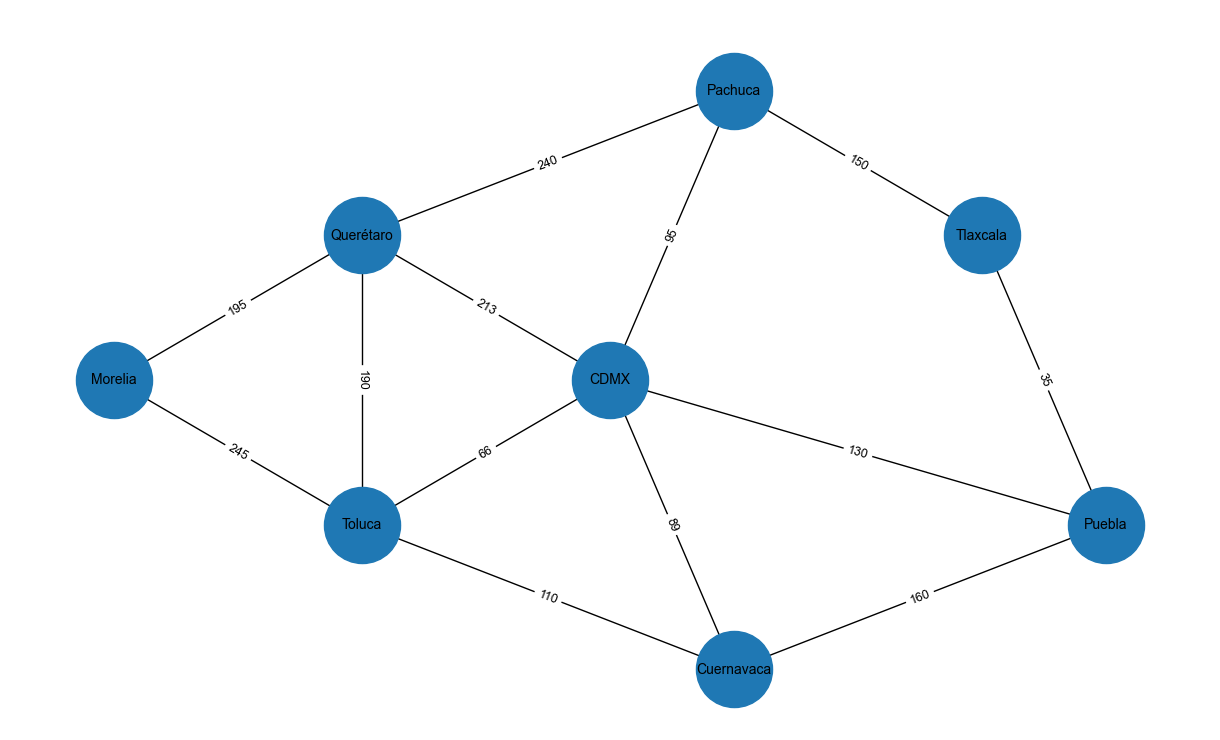

In [26]:
# ---------------------------------------------------------
# VISUALIZACIÓN DEL MAPA DE CARRETERAS
# ---------------------------------------------------------

# Definimos manualmente la posición de cada ciudad.
#
# Estas coordenadas NO representan coordenadas geográficas
# reales; solamente sirven para acomodar claramente los
# nodos dentro del dibujo.
posiciones = {
    "Morelia": (0, 2),
    "Querétaro": (2, 3),
    "Toluca": (2, 1),
    "CDMX": (4, 2),
    "Pachuca": (5, 4),
    "Cuernavaca": (5, 0),
    "Tlaxcala": (7, 3),
    "Puebla": (8, 1)
}

# Creamos una figura suficientemente grande para que
# los nombres y las distancias puedan leerse claramente.
plt.figure(figsize=(12, 7))

# Dibujamos los nodos, las conexiones y los nombres
# de las ciudades.
nx.draw(
    G,
    posiciones,
    with_labels=True,
    node_size=3000,
    font_size=10
)

# Obtenemos las distancias almacenadas en el atributo
# "weight" de cada carretera.
etiquetas_distancias = nx.get_edge_attributes(
    G,
    "weight"
)

# Dibujamos la distancia correspondiente sobre
# cada carretera.
nx.draw_networkx_edge_labels(
    G,
    posiciones,
    edge_labels=etiquetas_distancias,
    font_size=9
)

# Agregamos un título al gráfico.
plt.title(
    "Mapa de carreteras: búsqueda de Morelia a Puebla"
)

# Eliminamos los ejes porque no representan
# coordenadas geográficas reales.
plt.axis("off")

# Mostramos finalmente el grafo.
plt.show()

### Modelado del problema

El mapa de carreteras se representa mediante un grafo en el que:

- **Estados:** cada ciudad representa un estado del problema.
- **Estado inicial:** Morelia.
- **Estado meta:** Puebla.
- **Acciones:** desplazarse desde la ciudad actual hacia cualquiera de las ciudades conectadas directamente por una carretera.
- **Modelo de transición:** al recorrer una carretera, la ciudad destino se convierte en el nuevo estado.
- **Costo de paso:** distancia en kilómetros correspondiente a la carretera recorrida.
- **Costo de una ruta:** suma de las distancias de todos los tramos que forman la ruta.

Aunque cada carretera se visualiza mediante una sola arista en el gráfico, para los algoritmos se modela en ambos sentidos, es decir, como dos arcos dirigidos.

## Análisis comparativo de los resultados

### ¿Qué algoritmo encontró la ruta más corta en número de tramos?

BFS e IDS encontraron una ruta de **3 tramos**:

**Morelia → Querétaro → CDMX → Puebla**

UCS también encontró una ruta de 3 tramos, aunque por un recorrido diferente:

**Morelia → Toluca → CDMX → Puebla**

Por lo tanto, el menor número de tramos encontrado fue **3**.

BFS encuentra una solución con el menor número de tramos porque explora el espacio de estados por niveles de profundidad. IDS también encuentra una solución a la menor profundidad al repetir búsquedas limitadas incrementando progresivamente el límite.

DFS, en cambio, encontró una ruta de 4 tramos porque profundiza por una rama antes de explorar otras alternativas y no garantiza encontrar la solución de menor profundidad.

### ¿Qué algoritmo encontró la ruta más corta en kilómetros?

UCS encontró la ruta de menor costo:

**Morelia → Toluca → CDMX → Puebla**

con una distancia total de **441 km**.

BFS e IDS encontraron una ruta de **538 km**, mientras que DFS encontró una de **657 km**.

La diferencia se debe a que UCS selecciona para expandir el nodo con el menor costo acumulado. Por ello, toma en cuenta las distancias de las carreteras durante la búsqueda.

BFS e IDS priorizan la profundidad de la solución y no el costo de los tramos. Por esta razón, una ruta con el menor número de tramos no necesariamente es también la ruta con la menor distancia en kilómetros.

### Nodos expandidos

En esta implementación se obtuvieron los siguientes resultados:

- BFS: 6 nodos expandidos.
- DFS: 4 nodos expandidos.
- IDS: 7 nodos expandidos.
- UCS: 6 nodos expandidos.

DFS expandió menos nodos, pero esto no significa que haya encontrado una mejor solución: su ruta fue de 4 tramos y 657 km.

IDS acumuló 7 nodos expandidos debido a que realiza búsquedas sucesivas aumentando el límite de profundidad. Encontró la solución cuando el límite llegó a **3**.

### Completitud, optimalidad y complejidad

**BFS (Búsqueda en anchura):**
BFS es completa cuando el factor de ramificación es finito, por lo que encontrará una solución si esta existe. Es óptima cuando todos los costos de las acciones son iguales. Su complejidad temporal y espacial es O(b^d), donde `b` es el factor de ramificación y `d` la profundidad de la solución más superficial. Su principal desventaja es el consumo de memoria.

**DFS (Búsqueda en profundidad):**
DFS no es completa en espacios infinitos o cuando existen ciclos si estos no se controlan adecuadamente, y tampoco garantiza encontrar una solución óptima. Su complejidad temporal es O(b^m) y su complejidad espacial es O(bm), donde `m` representa la profundidad máxima del espacio de estados. En este experimento expandió pocos nodos, pero encontró una ruta de mayor costo y con más tramos.

**IDS (Búsqueda de profundidad iterativa):**
IDS es completa cuando el factor de ramificación es finito y es óptima cuando todos los costos de las acciones son iguales. Su complejidad temporal es O(b^d) y su complejidad espacial es O(bd). Combina la exploración por profundidad con el incremento progresivo del límite. En este problema encontró la solución al alcanzar el límite de profundidad 3.

**UCS (Búsqueda de costo uniforme):**
UCS es completa cuando los costos de las acciones son mayores o iguales a un valor positivo y es óptima para costos positivos. Expande primero el nodo que presenta el menor costo acumulado. Por esta razón encontró la ruta de menor distancia del experimento, con un costo total de 441 km. Su consumo de tiempo y memoria puede ser elevado debido a la cantidad de nodos que debe conservar en la frontera.

## Conclusiones

La práctica permitió comprobar que la estrategia utilizada para explorar un espacio de estados influye directamente en la solución obtenida.

BFS e IDS encontraron soluciones con el menor número de tramos, mientras que UCS encontró la ruta de menor costo en kilómetros. Esto demuestra que minimizar la profundidad de una solución no necesariamente equivale a minimizar su costo.

DFS expandió menos nodos en esta ejecución, pero encontró una ruta de mayor longitud y costo. Por lo tanto, un menor número de nodos expandidos no implica necesariamente una solución de mayor calidad.

UCS obtuvo la ruta Morelia → Toluca → CDMX → Puebla con un costo de 441 km, mientras que BFS e IDS obtuvieron una ruta de 538 km. IDS encontró su solución al alcanzar un límite de profundidad de 3.

Los resultados permiten observar que no existe una única estrategia de búsqueda adecuada para todos los problemas. La elección del algoritmo depende de las características del problema y del criterio que se desea optimizar, como el número de acciones, el costo de la solución o el uso de memoria.